In [86]:
import matplotlib.pyplot as plt    
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'   
# matplotlib.rcParams['font.family'] = 'AppleGothic'
matplotlib.rcParams['axes.unicode_minus']=False
import pandas as pd                  
import numpy as np                    
from sklearn import svm,metrics
from sklearn.model_selection import train_test_split    
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler

1.데이터 전처리
- length, weight 합치기
- 라벨값 생성

2.훈련데이터,테스트데이터 분리

3.표준점수 적용


4.데이터 학습

5.데이터 예측

6.정확도

7.그래프 출력

In [87]:
#도미-35
bream_length = [25.4, 26.3, 26.5, 29.0, 29.0, 29.7, 29.7, 30.0, 30.0, 30.7, 31.0, 31.0, 31.5, 32.0, 32.0, 32.0, 33.0, 33.0, 33.5, 33.5, 34.0, 34.0, 34.5, 35.0, 35.0, 35.0, 35.0, 36.0, 36.0, 37.0, 38.5, 38.5, 39.5, 41.0, 41.0]
bream_weight = [242.0, 290.0, 340.0, 363.0, 430.0, 450.0, 500.0, 390.0, 450.0, 500.0, 475.0, 500.0, 500.0, 340.0, 600.0, 600.0, 700.0, 700.0, 610.0, 650.0, 575.0, 685.0, 620.0, 680.0, 700.0, 725.0, 720.0, 714.0, 850.0, 1000.0, 920.0, 955.0, 925.0, 975.0, 950.0]

#빙어-14
smelt_length = [9.8, 10.5, 10.6, 11.0, 11.2, 11.3, 11.8, 11.8, 12.0, 12.2, 12.4, 13.0, 14.3, 15.0]
smelt_weight = [6.7, 7.5, 7.0, 9.7, 9.8, 8.7, 10.0, 9.9, 9.8, 12.2, 13.4, 12.2, 19.7, 19.9]

length = bream_length + smelt_length
weight = bream_weight + smelt_weight

In [88]:
#표준점수를 적용해서 전체 데이터와 [25,120]를 scatter그래프에 출력하시오.

In [89]:
# 합치기 ,라벨값
#1:도미 0:빙어
data= np.column_stack((length,weight))
label = [1]*35+[0]*14

In [90]:
#정규화가 안된 형태 - 훈련데이터,테스트데이터 분리
train_data,test_data,train_label,test_label=\
train_test_split(data,label)

In [91]:
test_data[:,0]

array([29.7, 31. , 30.7, 34.5, 15. , 35. , 11.2, 30. , 33. , 31.5, 38.5,
       35. , 32. ])

# 정규화작업-표준점수 적용

In [92]:
# # 평균구하기(전체 길이,무게의 평균) / axis=0 : 행동을 따라 내려가면서,각 열을 따로 계산한다
# # std =표준편차-데이터 평균 주변에 얼마나 퍼져 있는지 나타냄
# mean = np.mean(data,axis=0)
# std = np.std(data,axis=0)
# #표준점수로 변환
# train_scaled = (data-mean)/std
# new_data = ([25,150]-mean)/std
# new_data2 = ([29.5,300]-mean)/std

In [93]:
# train_data,test_data,train_label,test_label = \
# train_test_split(train_scaled,label)    # train_scaled (-1.5 - 1.5)

In [94]:
# 규제,정규화 작업
ss = StandardScaler()
#
ss.fit(train_data)    #정규화 데이터로 훈련 시켜줌.
train_scaled = ss.transform(train_data)
test_scaled = ss.transform(test_data)
new_scaled = ss.transform([[25,120]])
new_scaled

array([[-0.09965227, -0.89099575]])

In [95]:
#데이터 학습 
clf = KNeighborsClassifier()
clf.fit(train_scaled,train_label)
#데이터 예측
result =clf.predict(test_scaled)
#정확도
score = clf.score(test_scaled,test_label)
print('예측: ',score)

# kneighbors 알고리즘 사용시 
distances,indexes = clf.kneighbors(new_scaled)
indexes

예측:  1.0


array([[27, 18, 15,  6,  8]])

In [96]:
new_scaled

array([[-0.09965227, -0.89099575]])

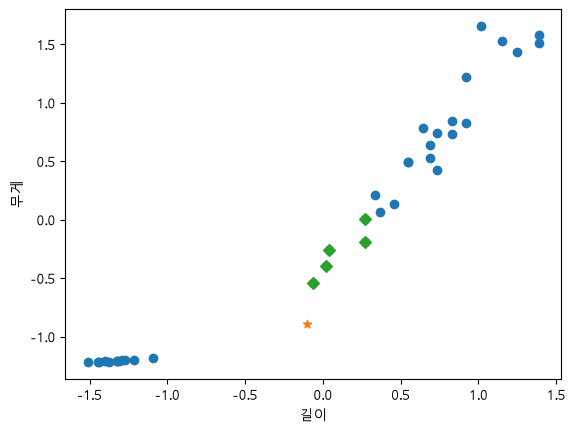

In [97]:
plt.scatter(train_scaled[:,0],train_scaled[:,1])
plt.scatter(new_scaled[:,0],new_scaled[:,1],marker='*')
plt.scatter(train_scaled[indexes,0],train_scaled[indexes,1],marker='D')
plt.xlabel('길이')
plt.ylabel('무게')
plt.show()